# Lab 8: Decision Trees and Support Vector Machines
**Dataset:** UCI Banknote Authentication (1,372 samples, 4 features, 2 classes)

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.datasets import make_moons
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

np.random.seed(42)
CMAP = ListedColormap(["#4c72b0", "#dd8452"])

## 1. Load data and split

In [2]:
cols = ["variance", "skewness", "curtosis", "entropy", "class"]
df = pd.read_csv("data_banknote_authentication.txt", header=None, names=cols)

print(df.shape)
print(df["class"].value_counts().to_string())
print(df.head().to_string())

(1372, 5)
class
0    762
1    610
   variance  skewness  curtosis  entropy  class
0   3.62160    8.6661   -2.8073 -0.44699      0
1   4.54590    8.1674   -2.4586 -1.46210      0
2   3.86600   -2.6383    1.9242  0.10645      0
3   3.45660    9.5228   -4.0112 -3.59440      0
4   0.32924   -4.4552    4.5718 -0.98880      0


In [3]:
X_all = df[cols[:4]].values
y_all = df["class"].values.astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.2, random_state=42, stratify=y_all)

# two-feature views: variance and skewness (first two columns)
X2_train, X2_test = X_train[:, :2], X_test[:, :2]
feat2 = ["variance", "skewness"]

print("train:", X_train.shape, " test:", X_test.shape)

train: (1097, 4)  test: (275, 4)


## Part A: Decision Tree
### A1. Impurity measures and best split

In [4]:
def gini(y):
    if len(y) == 0:
        return 0.0
    p = np.bincount(y, minlength=2) / len(y)
    return 1.0 - np.sum(p ** 2)

def entropy(y):
    if len(y) == 0:
        return 0.0
    p = np.bincount(y, minlength=2) / len(y)
    p = p[p > 0]
    return float(-np.sum(p * np.log2(p))) + 0.0

IMPURITY = {"gini": gini, "entropy": entropy}

def best_split(X, y, criterion="gini", min_samples_leaf=1):
    imp = IMPURITY[criterion]
    n, d = X.shape
    parent = imp(y)
    best = {"gain": 0.0, "feature": None, "threshold": None}
    for f in range(d):
        order = np.argsort(X[:, f], kind="stable")
        xs, ys = X[order, f], y[order]
        for i in range(min_samples_leaf, n - min_samples_leaf + 1):
            if xs[i - 1] == xs[i]:
                continue
            left, right = ys[:i], ys[i:]
            child = (len(left) * imp(left) + len(right) * imp(right)) / n
            gain = parent - child
            if gain > best["gain"] + 1e-12:
                best = {"gain": gain, "feature": f, "threshold": (xs[i - 1] + xs[i]) / 2}
    return best

print("gini([0,0,1,1]) =", gini(np.array([0, 0, 1, 1])), "| entropy([0,0,1,1]) =", entropy(np.array([0, 0, 1, 1])))
print("gini(pure) =", gini(np.array([1, 1, 1])), "| entropy(pure) =", entropy(np.array([1, 1, 1])))
print("best root split (variance, skewness):", best_split(X2_train, y_train))

gini([0,0,1,1]) = 0.5 | entropy([0,0,1,1]) = 1.0
gini(pure) = 0.0 | entropy(pure) = 0.0
best root split (variance, skewness): {'gain': np.float64(0.24209450956617234), 'feature': 0, 'threshold': np.float64(0.7651)}


### A2. Recursive tree
Stop when: max depth reached, node is pure, too few samples to split, or no split gives a positive gain.

In [5]:
class DecisionTreeScratch:
    def __init__(self, criterion="gini", max_depth=None, min_samples_split=2, min_samples_leaf=1):
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf

    def fit(self, X, y):
        self.root = self._build(X, y, 0)
        return self

    def _build(self, X, y, depth):
        counts = np.bincount(y, minlength=2)
        node = {"leaf": True, "pred": int(counts.argmax()), "samples": len(y),
                "counts": counts, "impurity": IMPURITY[self.criterion](y)}
        if (self.max_depth is not None and depth >= self.max_depth) \
                or len(y) < self.min_samples_split or node["impurity"] == 0:
            return node
        s = best_split(X, y, self.criterion, self.min_samples_leaf)
        if s["feature"] is None:
            return node
        mask = X[:, s["feature"]] <= s["threshold"]
        node.update(leaf=False, feature=s["feature"], threshold=s["threshold"],
                    left=self._build(X[mask], y[mask], depth + 1),
                    right=self._build(X[~mask], y[~mask], depth + 1))
        return node

    def predict(self, X):
        out = np.zeros(len(X), dtype=int)
        self._predict(self.root, X, np.arange(len(X)), out)
        return out

    def _predict(self, node, X, idx, out):
        if node["leaf"]:
            out[idx] = node["pred"]
            return
        go_left = X[idx, node["feature"]] <= node["threshold"]
        self._predict(node["left"], X, idx[go_left], out)
        self._predict(node["right"], X, idx[~go_left], out)

    def depth(self):
        def d(n):
            return 0 if n["leaf"] else 1 + max(d(n["left"]), d(n["right"]))
        return d(self.root)

    def n_leaves(self):
        def c(n):
            return 1 if n["leaf"] else c(n["left"]) + c(n["right"])
        return c(self.root)

tree = DecisionTreeScratch("gini", max_depth=5).fit(X2_train, y_train)
print("depth:", tree.depth(), "| leaves:", tree.n_leaves())
print("train acc:", accuracy_score(y_train, tree.predict(X2_train)))
print("test acc :", accuracy_score(y_test, tree.predict(X2_test)))

depth: 5 | leaves: 22
train acc: 0.9480401093892434
test acc : 0.9309090909090909


### A3. Visualize the learned tree

if variance <= 0.765:
|   if skewness <= 5.161:
|   |   if variance <= 0.320:
|   |   |   -> class 1  (n=413, counts=[20, 393])
|   |   else:  # variance > 0.320
|   |   |   -> class 1  (n=51, counts=[22, 29])
|   else:  # skewness > 5.161
|   |   if variance <= -3.431:
|   |   |   -> class 1  (n=32, counts=[1, 31])
|   |   else:  # variance > -3.431
|   |   |   -> class 0  (n=97, counts=[96, 1])
else:  # variance > 0.765
|   if variance <= 1.791:
|   |   if skewness <= 4.881:
|   |   |   -> class 0  (n=71, counts=[42, 29])
|   |   else:  # skewness > 4.881
|   |   |   -> class 0  (n=44, counts=[44, 0])
|   else:  # variance > 1.791
|   |   if variance <= 2.392:
|   |   |   -> class 0  (n=64, counts=[59, 5])
|   |   else:  # variance > 2.392
|   |   |   -> class 0  (n=325, counts=[325, 0])


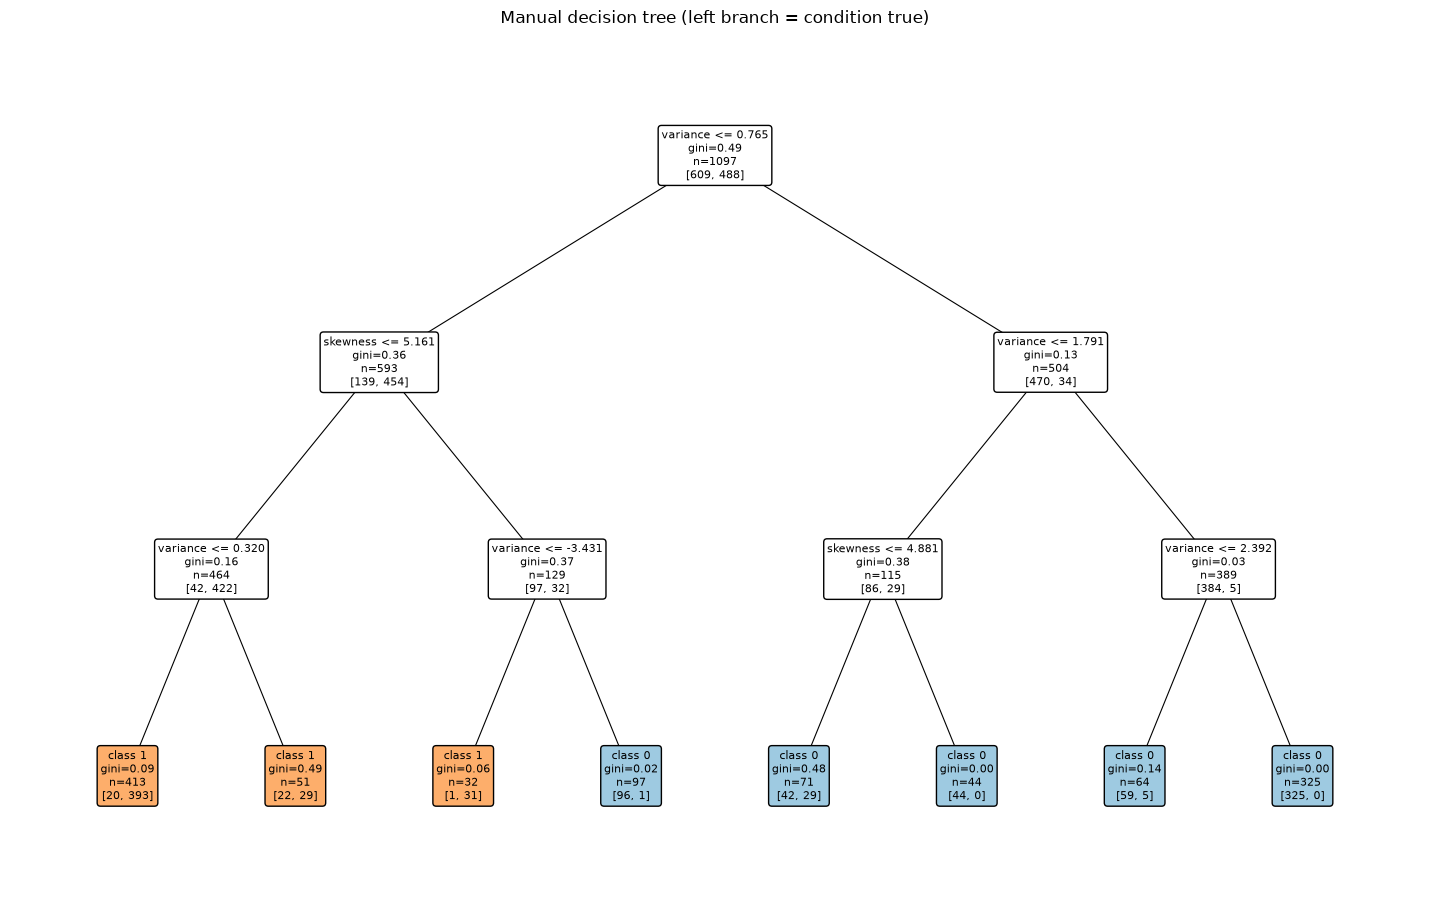

In [6]:
def print_rules(node, names, indent=0):
    pad = "|   " * indent
    if node["leaf"]:
        print(f"{pad}-> class {node['pred']}  (n={node['samples']}, counts={node['counts'].tolist()})")
        return
    print(f"{pad}if {names[node['feature']]} <= {node['threshold']:.3f}:")
    print_rules(node["left"], names, indent + 1)
    print(f"{pad}else:  # {names[node['feature']]} > {node['threshold']:.3f}")
    print_rules(node["right"], names, indent + 1)

def plot_tree_scratch(tree, names):
    leaves = []
    def layout(node, depth):
        node["depth"] = depth
        if node["leaf"]:
            node["x"] = len(leaves)
            leaves.append(node)
        else:
            layout(node["left"], depth + 1)
            layout(node["right"], depth + 1)
            node["x"] = (node["left"]["x"] + node["right"]["x"]) / 2
    layout(tree.root, 0)
    max_d = max(l["depth"] for l in leaves)

    fig, ax = plt.subplots(figsize=(max(8, len(leaves) * 1.8), 2.3 * (max_d + 1)))
    def draw(node):
        common = f"{tree.criterion}={node['impurity']:.2f}\nn={node['samples']}\n{node['counts'].tolist()}"
        if node["leaf"]:
            label = f"class {node['pred']}\n" + common
            color = "#9ecae1" if node["pred"] == 0 else "#fdae6b"
        else:
            label = f"{names[node['feature']]} <= {node['threshold']:.3f}\n" + common
            color = "white"
        ax.text(node["x"], -node["depth"], label, ha="center", va="center", fontsize=8,
                bbox=dict(boxstyle="round", fc=color, ec="k"))
        if not node["leaf"]:
            for child in (node["left"], node["right"]):
                ax.plot([node["x"], child["x"]], [-node["depth"], -child["depth"]], "k-", lw=0.8, zorder=0)
                draw(child)
    draw(tree.root)
    ax.set_xlim(-0.7, len(leaves) - 0.3)
    ax.set_ylim(-max_d - 0.6, 0.6)
    ax.axis("off")
    ax.set_title("Manual decision tree (left branch = condition true)")
    plt.tight_layout()
    plt.show()

tree3 = DecisionTreeScratch("gini", max_depth=3).fit(X2_train, y_train)
print_rules(tree3.root, feat2)
plot_tree_scratch(tree3, feat2)

### A4. Decision boundaries: manual vs Scikit-learn

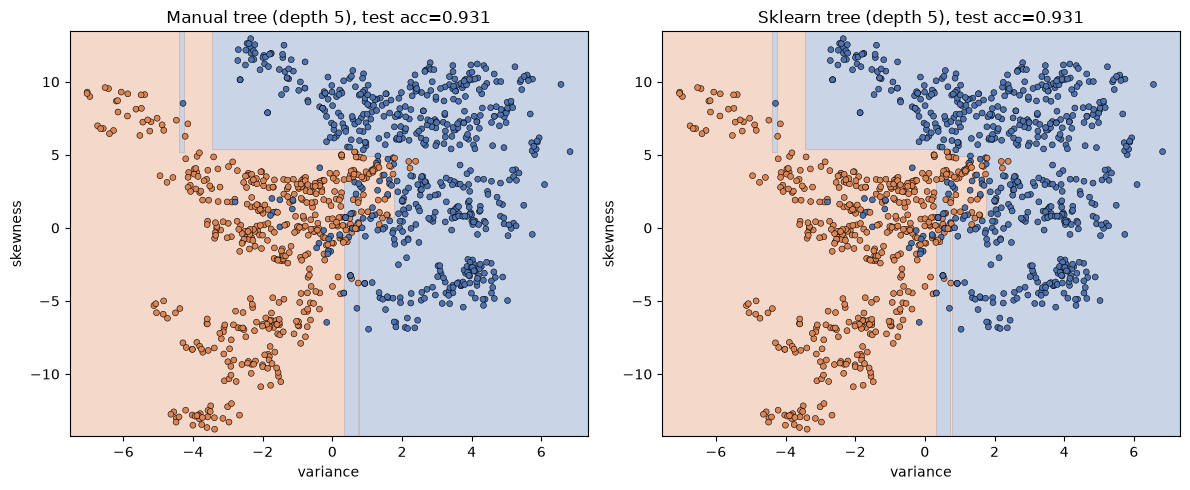

prediction agreement on test set: 1.0


In [7]:
def plot_boundary(predict_fn, X, y, ax, title, labels=("variance", "skewness"), mark=None):
    pad = 0.5
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, 300),
                         np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, 300))
    Z = predict_fn(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5], cmap=CMAP, alpha=0.3)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=CMAP, edgecolor="k", s=18, linewidth=0.4)
    ax.set_xlabel(labels[0]); ax.set_ylabel(labels[1]); ax.set_title(title)

man = DecisionTreeScratch("gini", max_depth=5).fit(X2_train, y_train)
sk = DecisionTreeClassifier(criterion="gini", max_depth=5, random_state=42).fit(X2_train, y_train)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_boundary(man.predict, X2_train, y_train, axes[0],
              f"Manual tree (depth 5), test acc={accuracy_score(y_test, man.predict(X2_test)):.3f}")
plot_boundary(sk.predict, X2_train, y_train, axes[1],
              f"Sklearn tree (depth 5), test acc={accuracy_score(y_test, sk.predict(X2_test)):.3f}")
plt.tight_layout(); plt.show()

print("prediction agreement on test set:", (man.predict(X2_test) == sk.predict(X2_test)).mean())

### A5. Criterion and max-depth exploration

In [8]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, None]
rows = []
for crit in ["gini", "entropy"]:
    for d in depths:
        m = DecisionTreeScratch(crit, max_depth=d).fit(X2_train, y_train)
        s = DecisionTreeClassifier(criterion=crit, max_depth=d, random_state=42).fit(X2_train, y_train)
        pm, ps = m.predict(X2_test), s.predict(X2_test)
        rows.append({"criterion": crit, "max_depth": "None" if d is None else d,
                     "manual_train": accuracy_score(y_train, m.predict(X2_train)),
                     "manual_test": accuracy_score(y_test, pm),
                     "sklearn_train": accuracy_score(y_train, s.predict(X2_train)),
                     "sklearn_test": accuracy_score(y_test, ps),
                     "agreement": (pm == ps).mean()})
res_tree = pd.DataFrame(rows)
print(res_tree.round(4).to_string(index=False))

criterion max_depth  manual_train  manual_test  sklearn_train  sklearn_test  agreement
     gini         1        0.8423       0.8291         0.8423        0.8291     1.0000
     gini         2        0.9015       0.8764         0.9015        0.8764     1.0000
     gini         3        0.9289       0.9091         0.9289        0.9091     1.0000
     gini         4        0.9435       0.9345         0.9435        0.9345     1.0000
     gini         5        0.9480       0.9309         0.9480        0.9309     1.0000
     gini         6        0.9572       0.9273         0.9572        0.9309     0.9964
     gini         8        0.9809       0.9164         0.9809        0.9200     0.9964
     gini        10        0.9954       0.9200         0.9954        0.9236     0.9964
     gini      None        1.0000       0.9200         1.0000        0.9200     0.9927
  entropy         1        0.8423       0.8291         0.8423        0.8291     1.0000
  entropy         2        0.9015       0.8

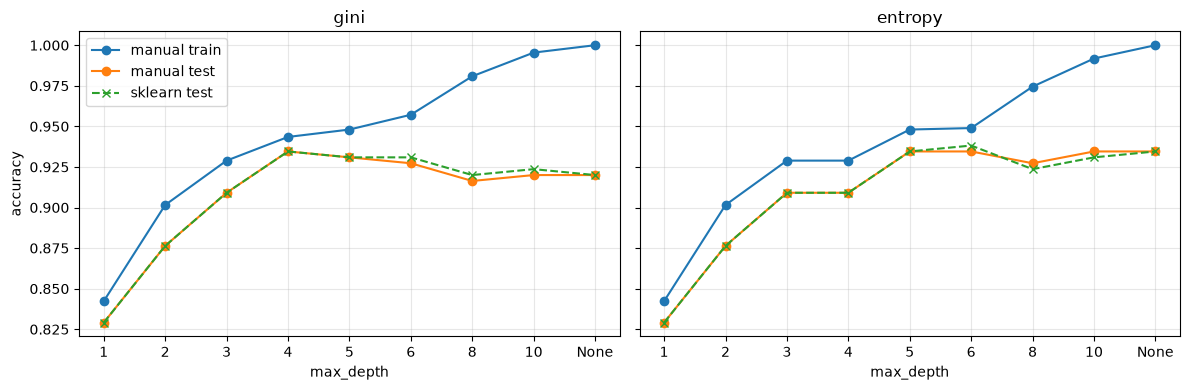

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, crit in zip(axes, ["gini", "entropy"]):
    r = res_tree[res_tree["criterion"] == crit]
    x = range(len(r))
    ax.plot(x, r["manual_train"], "o-", label="manual train")
    ax.plot(x, r["manual_test"], "o-", label="manual test")
    ax.plot(x, r["sklearn_test"], "x--", label="sklearn test")
    ax.set_xticks(list(x)); ax.set_xticklabels(r["max_depth"])
    ax.set_xlabel("max_depth"); ax.set_title(crit); ax.grid(alpha=0.3)
axes[0].set_ylabel("accuracy"); axes[0].legend()
plt.tight_layout(); plt.show()

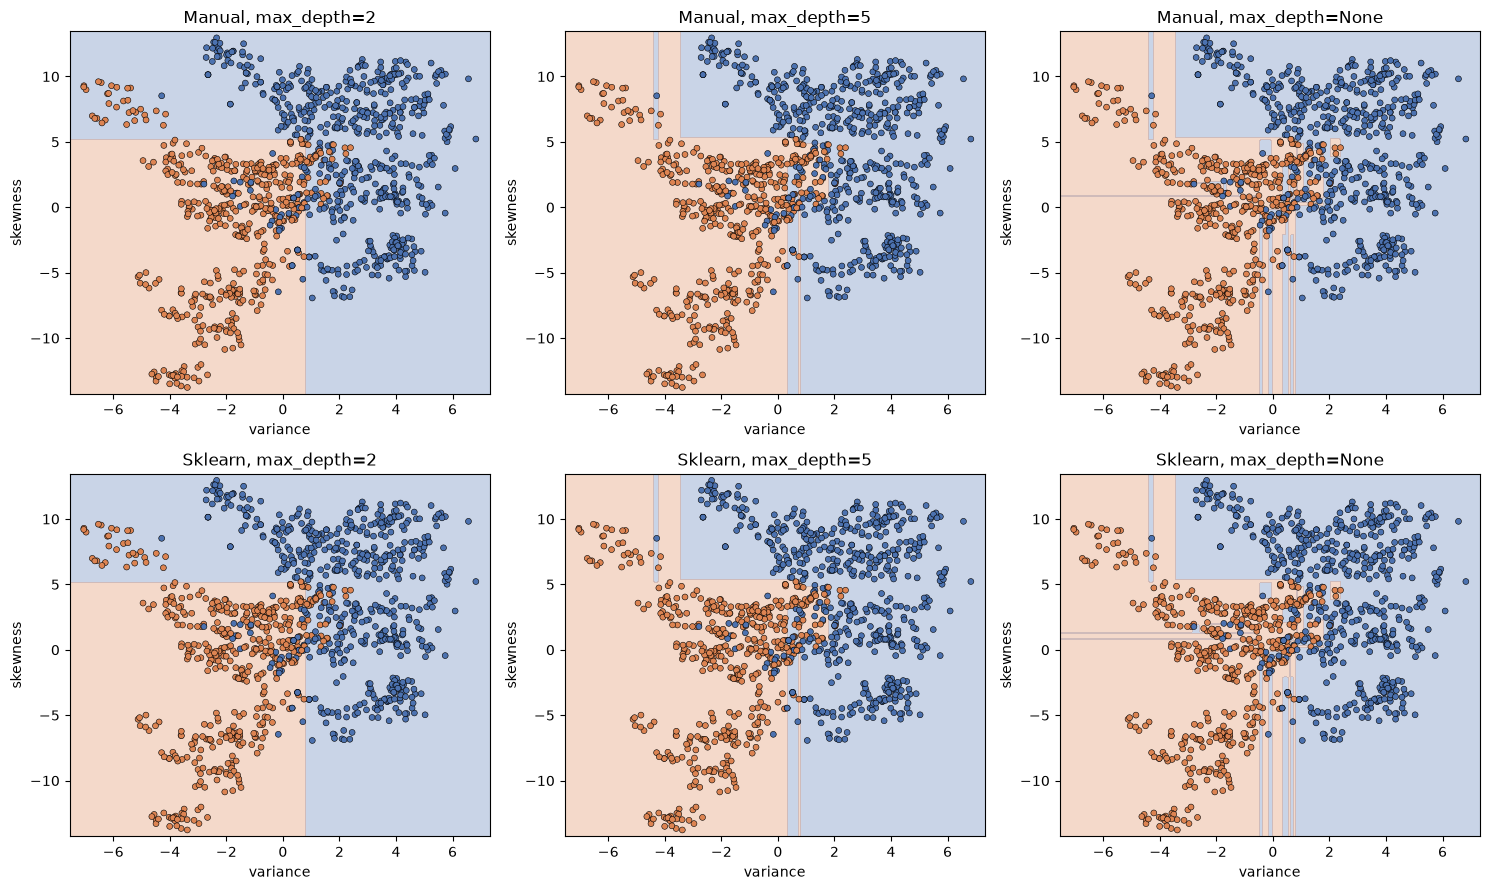

In [10]:
# boundaries for shallow / medium / unlimited depth (gini)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for j, d in enumerate([2, 5, None]):
    m = DecisionTreeScratch("gini", max_depth=d).fit(X2_train, y_train)
    s = DecisionTreeClassifier(criterion="gini", max_depth=d, random_state=42).fit(X2_train, y_train)
    plot_boundary(m.predict, X2_train, y_train, axes[0, j], f"Manual, max_depth={d}")
    plot_boundary(s.predict, X2_train, y_train, axes[1, j], f"Sklearn, max_depth={d}")
plt.tight_layout(); plt.show()

**Observations (Part A)**
- The manual tree matches Scikit-learn exactly up to depth 5 and agrees on more than 98% of test predictions at deeper settings (see the `agreement` column). Small differences come from tie-breaking between equally good splits.
- Gini and entropy give very similar trees and accuracy.
- Very shallow trees underfit. Unlimited depth reaches 100% train accuracy but test accuracy stops improving, so the boundary just gets more jagged (overfitting).

## Part B: Linear SVM
### B1. Scale features and map labels

In [11]:
mu2, sd2 = X2_train.mean(axis=0), X2_train.std(axis=0)
X2_train_s = (X2_train - mu2) / sd2
X2_test_s = (X2_test - mu2) / sd2

y_train_pm = np.where(y_train == 1, 1, -1)
y_test_pm = np.where(y_test == 1, 1, -1)

print("train mean after scaling:", X2_train_s.mean(axis=0).round(6), " std:", X2_train_s.std(axis=0).round(6))
print("labels:", np.unique(y_train_pm))

train mean after scaling: [-0. -0.]  std: [1. 1.]
labels: [-1  1]


### B2. Soft-margin SVM with hinge loss and subgradient descent

In [12]:
class LinearSVMScratch:
    def __init__(self, C=1.0, lr=0.1, n_iters=1000):
        self.C, self.lr, self.n_iters = C, lr, n_iters

    def fit(self, X, y):
        n, d = X.shape
        self.w, self.b = np.zeros(d), 0.0
        self.loss_history = []
        for _ in range(self.n_iters):
            margins = y * (X @ self.w + self.b)
            viol = margins < 1
            self.loss_history.append(self.w @ self.w / (2 * self.C * n) + np.maximum(0, 1 - margins).mean())
            grad_w = self.w / (self.C * n) - (y[viol, None] * X[viol]).sum(axis=0) / n
            grad_b = -y[viol].sum() / n
            self.w -= self.lr * grad_w
            self.b -= self.lr * grad_b
        return self

    def decision_function(self, X):
        return X @ self.w + self.b

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, -1)

svm = LinearSVMScratch(C=1.0, lr=0.1, n_iters=1000).fit(X2_train_s, y_train_pm)
print("w =", svm.w.round(4), " b =", round(svm.b, 4))
print("train acc:", accuracy_score(y_train_pm, svm.predict(X2_train_s)))
print("test acc :", accuracy_score(y_test_pm, svm.predict(X2_test_s)))

w = [-1.9819 -1.2372]  b = -0.2314
train acc: 0.8796718322698268
test acc : 0.8763636363636363


### B3. Boundary, margins and margin violators

manual margin violators: 316 | sklearn support vectors: 317


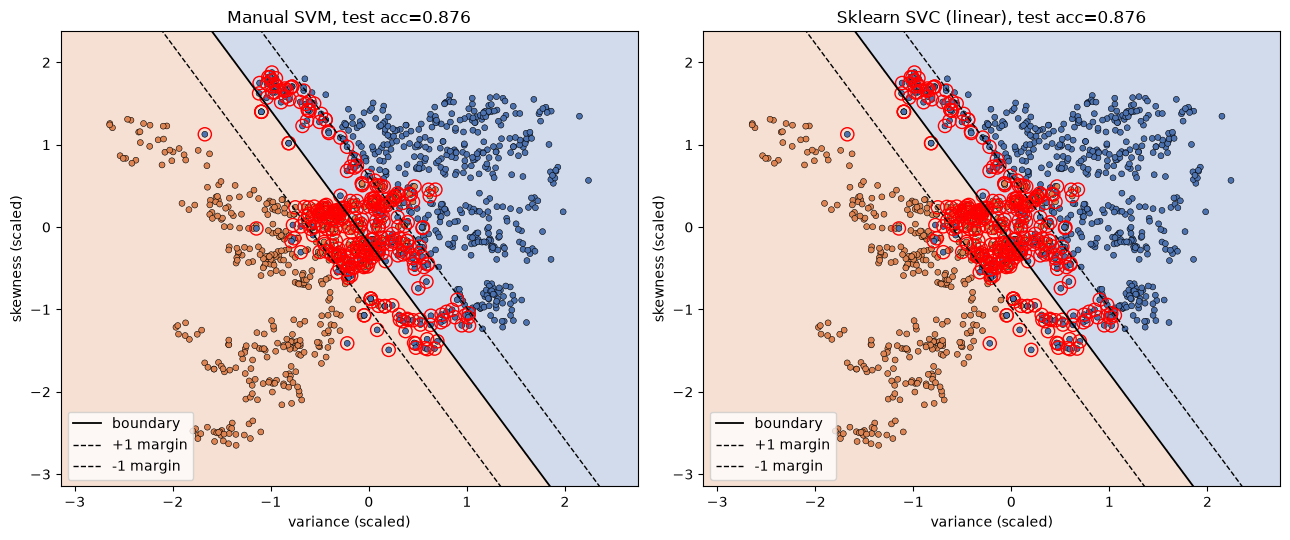

manual  w = [-1.9819 -1.2372]  b = -0.2314
sklearn w = [-2.0093 -1.255 ]  b = -0.2211


In [13]:
def plot_svm(w, b, X, y01, ax, title, highlight_idx):
    pad = 0.5
    x0 = np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, 300)
    xx, yy = np.meshgrid(x0, np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, 300))
    Z = ((np.c_[xx.ravel(), yy.ravel()] @ w + b) >= 0).astype(int).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5], cmap=CMAP, alpha=0.25)
    ax.scatter(X[:, 0], X[:, 1], c=y01, cmap=CMAP, edgecolor="k", s=18, linewidth=0.4)
    ax.scatter(X[highlight_idx, 0], X[highlight_idx, 1], s=90, facecolors="none", edgecolors="red", linewidths=1.0)
    for k, ls, lab in [(0, "-", "boundary"), (1, "--", "+1 margin"), (-1, "--", "-1 margin")]:
        ax.plot(x0, (k - b - w[0] * x0) / w[1], "k" + ls, lw=1.3 if k == 0 else 1, label=lab)
    ax.set_xlim(x0.min(), x0.max())
    ax.set_ylim(X[:, 1].min() - pad, X[:, 1].max() + pad)
    ax.set_xlabel("variance (scaled)"); ax.set_ylabel("skewness (scaled)")
    ax.set_title(title); ax.legend(loc="lower left")

sk_svm = SVC(kernel="linear", C=1.0).fit(X2_train_s, y_train_pm)
w_sk, b_sk = sk_svm.coef_[0], sk_svm.intercept_[0]

viol_idx = np.where(y_train_pm * svm.decision_function(X2_train_s) < 1)[0]
print("manual margin violators:", len(viol_idx), "| sklearn support vectors:", len(sk_svm.support_))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
plot_svm(svm.w, svm.b, X2_train_s, y_train, axes[0],
         f"Manual SVM, test acc={accuracy_score(y_test_pm, svm.predict(X2_test_s)):.3f}", viol_idx)
plot_svm(w_sk, b_sk, X2_train_s, y_train, axes[1],
         f"Sklearn SVC (linear), test acc={accuracy_score(y_test_pm, sk_svm.predict(X2_test_s)):.3f}", sk_svm.support_)
plt.tight_layout(); plt.show()

print("manual  w =", svm.w.round(4), " b =", round(svm.b, 4))
print("sklearn w =", w_sk.round(4), " b =", round(b_sk, 4))

### B4. Effect of C, learning rate and iterations

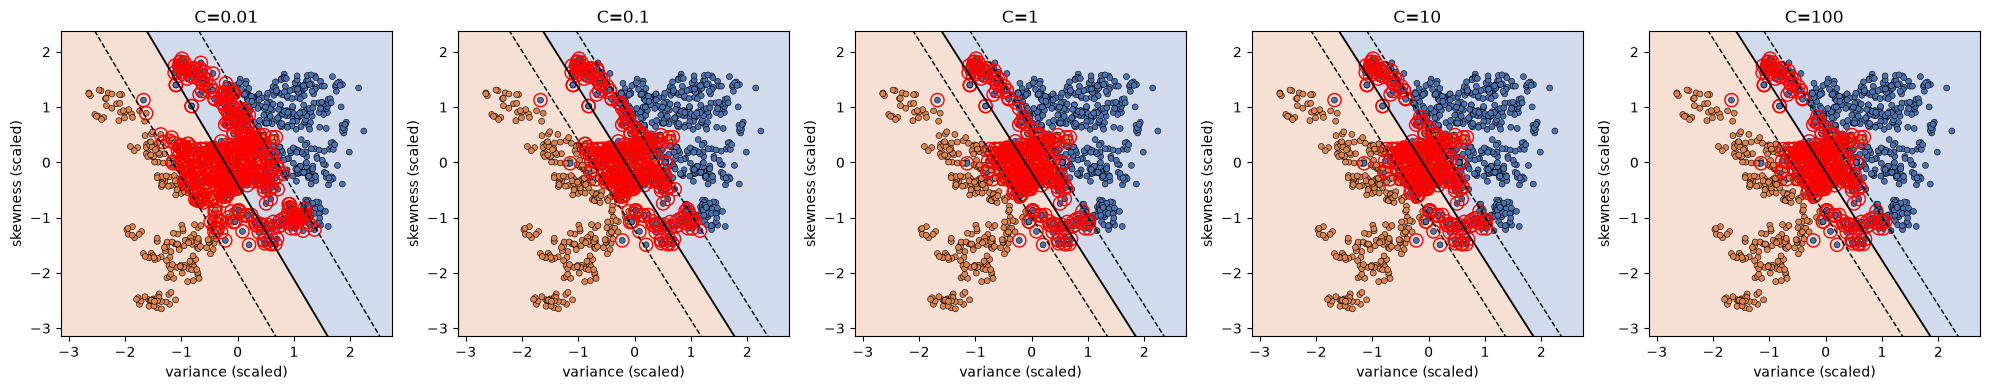

     C  manual_test  sklearn_test  manual_||w||  sklearn_||w||  manual_violators  sklearn_SVs
  0.01       0.8873        0.8873        1.2527         1.2530               515          516
  0.10       0.8836        0.8836        1.9822         1.9934               353          355
  1.00       0.8764        0.8764        2.3363         2.3690               316          317
 10.00       0.8764        0.8764        2.3836         2.4295               311          311
100.00       0.8764        0.8764        2.3892         2.4291               312          312


In [14]:
# effect of C
rows = []
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, C in zip(axes, [0.01, 0.1, 1, 10, 100]):
    m = LinearSVMScratch(C=C, lr=0.1, n_iters=1000).fit(X2_train_s, y_train_pm)
    s = SVC(kernel="linear", C=C).fit(X2_train_s, y_train_pm)
    v = (y_train_pm * m.decision_function(X2_train_s) < 1).sum()
    rows.append({"C": C, "manual_test": accuracy_score(y_test_pm, m.predict(X2_test_s)),
                 "sklearn_test": accuracy_score(y_test_pm, s.predict(X2_test_s)),
                 "manual_||w||": np.linalg.norm(m.w), "sklearn_||w||": np.linalg.norm(s.coef_[0]),
                 "manual_violators": v, "sklearn_SVs": len(s.support_)})
    plot_svm(m.w, m.b, X2_train_s, y_train, ax, f"C={C}", np.where(y_train_pm * m.decision_function(X2_train_s) < 1)[0])
    ax.legend().remove()
plt.tight_layout(); plt.show()
print(pd.DataFrame(rows).round(4).to_string(index=False))

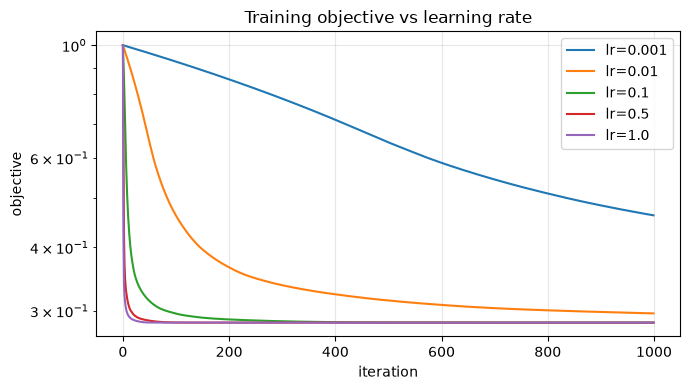

   lr  final_loss  test_acc
0.001      0.4625    0.8873
0.010      0.2965    0.8873
0.100      0.2844    0.8764
0.500      0.2844    0.8764
1.000      0.2844    0.8764

 iterations  final_loss  test_acc
          5      0.7131    0.8764
         10      0.4779    0.8873
         50      0.3143    0.8873
        100      0.2965    0.8873
        500      0.2846    0.8800
       1000      0.2844    0.8764
       5000      0.2844    0.8764


In [15]:
# effect of learning rate (1000 iterations, C=1)
rows = []
plt.figure(figsize=(7, 4))
for lr in [0.001, 0.01, 0.1, 0.5, 1.0]:
    m = LinearSVMScratch(C=1, lr=lr, n_iters=1000).fit(X2_train_s, y_train_pm)
    plt.plot(m.loss_history, label=f"lr={lr}")
    rows.append({"lr": lr, "final_loss": m.loss_history[-1], "test_acc": accuracy_score(y_test_pm, m.predict(X2_test_s))})
plt.yscale("log"); plt.xlabel("iteration"); plt.ylabel("objective"); plt.title("Training objective vs learning rate")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
print(pd.DataFrame(rows).round(4).to_string(index=False))

# effect of number of iterations (lr=0.1, C=1)
rows = []
for it in [5, 10, 50, 100, 500, 1000, 5000]:
    m = LinearSVMScratch(C=1, lr=0.1, n_iters=it).fit(X2_train_s, y_train_pm)
    rows.append({"iterations": it, "final_loss": m.loss_history[-1], "test_acc": accuracy_score(y_test_pm, m.predict(X2_test_s))})
print()
print(pd.DataFrame(rows).round(4).to_string(index=False))

**Observations (Part B)**
- The manual SVM learns almost the same `w` and `b` as Scikit-learn and gives the same test accuracy.
- Small C = strong regularization: smaller `||w||`, wider margin, many margin violators. Large C = narrow margin, fewer violators.
- A very small learning rate (0.001) converges slowly and is still far from the optimum after 1000 iterations. Rates of 0.1 and above reach the same final loss quickly on this scaled data.
- Few iterations leave the model undertrained; after a few hundred iterations the loss stops improving. Test accuracy barely changes (about 0.88) because the two-feature data is the limit, not the optimizer.
- With only variance and skewness the classes are not perfectly linearly separable, so some violators always remain.

## Part C: Kernel SVM and Nonlinear Boundaries

Linear                 train acc=0.813  test acc=0.920
Polynomial (degree 3)  train acc=0.940  test acc=0.930
RBF                    train acc=0.933  test acc=0.950


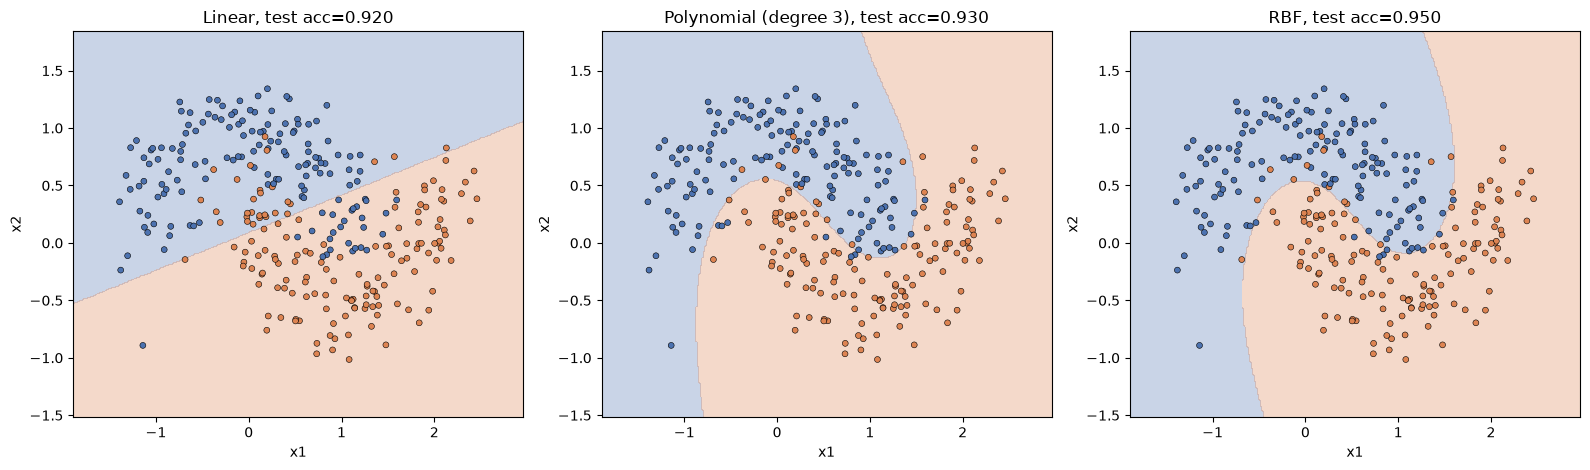

In [16]:
Xm, ym = make_moons(n_samples=400, noise=0.25, random_state=42)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.25, random_state=42, stratify=ym)

kernels = {
    "Linear": SVC(kernel="linear", C=1),
    "Polynomial (degree 3)": SVC(kernel="poly", degree=3, coef0=1, C=1),
    "RBF": SVC(kernel="rbf", gamma="scale", C=1),
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (name, model) in zip(axes, kernels.items()):
    model.fit(Xm_tr, ym_tr)
    acc = accuracy_score(ym_te, model.predict(Xm_te))
    plot_boundary(model.predict, Xm_tr, ym_tr, ax, f"{name}, test acc={acc:.3f}", labels=("x1", "x2"))
    print(f"{name:22s} train acc={accuracy_score(ym_tr, model.predict(Xm_tr)):.3f}  test acc={acc:.3f}")
plt.tight_layout(); plt.show()

**Why a nonlinear kernel**
- The two moons cannot be separated by a straight line, so the linear kernel must misclassify many points.
- A kernel lets the SVM act as if the data were mapped to a higher-dimensional space where a linear separator exists, without computing that mapping. The boundary looks curved in the original 2D space.
- Polynomial gives a smooth global curve. RBF is the most flexible and follows the local shape of each moon, so it fits best here.

## Part D: Final Comparison
Trees use raw features; SVMs use features scaled with training statistics.

In [17]:
mu4, sd4 = X_train.mean(axis=0), X_train.std(axis=0)
X_train_s, X_test_s = (X_train - mu4) / sd4, (X_test - mu4) / sd4
pm = lambda p: (p > 0).astype(int)   # convert -1/+1 predictions back to 0/1

models = {
    "Manual Tree":        (DecisionTreeScratch("gini", max_depth=5), X_train, X_test, lambda p: p),
    "Sklearn Tree":       (DecisionTreeClassifier(criterion="gini", max_depth=5, random_state=42), X_train, X_test, lambda p: p),
    "Manual Linear SVM":  (LinearSVMScratch(C=1, lr=0.1, n_iters=1000), X_train_s, X_test_s, pm),
    "Sklearn Linear SVM": (SVC(kernel="linear", C=1), X_train_s, X_test_s, pm),
    "RBF SVM":            (SVC(kernel="rbf", C=1, gamma="scale"), X_train_s, X_test_s, pm),
}

rows = []
for name, (model, Xtr, Xte, to01) in models.items():
    ytr = y_train_pm if "SVM" in name else y_train
    t0 = time.perf_counter(); model.fit(Xtr, ytr); fit_t = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = to01(model.predict(Xte)); pred_t = time.perf_counter() - t0
    rows.append({"model": name,
                 "train_acc": accuracy_score(y_train, to01(model.predict(Xtr))),
                 "accuracy": accuracy_score(y_test, pred),
                 "precision": precision_score(y_test, pred),
                 "recall": recall_score(y_test, pred),
                 "f1": f1_score(y_test, pred),
                 "train_time_s": fit_t, "predict_time_s": pred_t})
results = pd.DataFrame(rows).set_index("model")
print(results.round(4).to_string())

                    train_acc  accuracy  precision  recall      f1  train_time_s  predict_time_s
model                                                                                           
Manual Tree            0.9945    0.9927     0.9839     1.0  0.9919        0.3235          0.0003
Sklearn Tree           0.9945    0.9927     0.9839     1.0  0.9919        0.0074          0.0004
Manual Linear SVM      0.9854    0.9709     0.9385     1.0  0.9683        0.0806          0.0001
Sklearn Linear SVM     0.9863    0.9745     0.9457     1.0  0.9721        0.0089          0.0006
RBF SVM                1.0000    1.0000     1.0000     1.0  1.0000        0.0063          0.0025


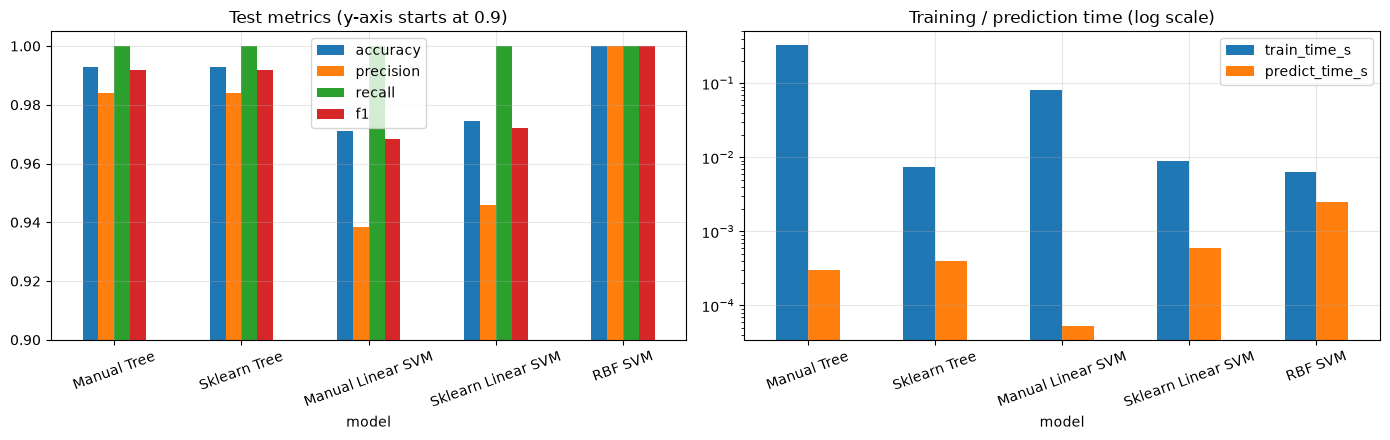

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
results[["accuracy", "precision", "recall", "f1"]].plot.bar(ax=axes[0], rot=20)
axes[0].set_ylim(0.9, 1.005); axes[0].set_title("Test metrics (y-axis starts at 0.9)"); axes[0].grid(alpha=0.3)
results[["train_time_s", "predict_time_s"]].plot.bar(ax=axes[1], rot=20, logy=True)
axes[1].set_title("Training / prediction time (log scale)"); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()